# error analysis of model predicition

In [ ]:
import ast
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parents[0]
PROMPTING_PATH = PROJECT_ROOT / "outputs" / "predictions" / "prompting"

models = ["3B", "7B"]
modes = ["zero_shot", "five_shot"]
targets = ["english", "de", "sv"]

all_dfs_prompting_values = []
all_dfs_prompting_metrics = []

for mode in modes:
    for model in models:
        for target in targets:
            file_path = PROMPTING_PATH / mode / f"test_{model}_{target}_predictions.csv"

            if file_path.exists():
                df = pd.read_csv(file_path)
                # Tag the rows so you know which condition generated them
                df["model"] = model
                df["mode"] = mode
                df["target"] = target
                all_dfs_prompting_values.append(df)
            else:
                print(f"Warning: Could not find {file_path}")

# This master DataFrame is perfect for groupby operations and Seaborn plotting
prompting_values_df = pd.concat(all_dfs_prompting_values, ignore_index=True)

# load all the metrics for the prompting experiments
for mode in modes:
    for model in models:
        for target in targets:
            file_path = PROMPTING_PATH / mode / f"test_{model}_{target}_metrics.json"

            if file_path.exists():
                df = pd.read_json(file_path)
                # Tag the rows so you know which condition generated them
                df["model"] = model
                df["mode"] = mode
                df["target"] = target
                all_dfs_prompting_metrics.append(df)
            else:
                print(f"Warning: Could not find {file_path}")

prompting_metrics_df = pd.concat(all_dfs_prompting_metrics, ignore_index=True)

# Extract metrics cleanly from the JSON files directly also add direct F1 score and all that here per emotion
metrics_records = []
for mode in modes:
    for model in models:
        for target in targets:
            file_path = PROMPTING_PATH / mode / f"test_{model}_{target}_metrics.json"
            if file_path.exists():
                with open(file_path, "r") as f:
                    data = json.load(f)
                    metrics_records.append({
                        "model": model,
                        "mode": mode,
                        "target": target,
                        "micro_precision": data["secondary"]["micro_precision"],
                        "micro_recall": data["secondary"]["micro_recall"],
                        "micro_f1": data["primary"]["micro_f1"],
                        
                        
                    })

metrics_summary_df = pd.DataFrame(metrics_records)


# sanitize columns
def safe_parse_list(val):
    if isinstance(val, list):
        return val
    try:
        return ast.literal_eval(val)
    except (ValueError, SyntaxError):
        return []

# Apply to the long-format values DataFrame
prompting_values_df["true_labels"] = prompting_values_df["true_labels"].apply(safe_parse_list)
prompting_values_df["normalized_prediction"] = prompting_values_df["normalized_prediction"].apply(safe_parse_list)

# Re-pivot with the cleaned lists
prompting_comparison_df = prompting_values_df.pivot_table(
    index=["alignment_id"], # true_labels removed from index to avoid tuple grouping issues
    columns=["model", "mode", "target"], 
    values="normalized_prediction", 
    aggfunc="first"
)

# Bring true labels back using the same three-level column structure
true_labels_df = (
    prompting_values_df
    .drop_duplicates("alignment_id")
    .set_index("alignment_id")["true_labels"]
    .reindex(prompting_comparison_df.index)
)

prompting_comparison_df[("metadata", "metadata", "true_labels")] = true_labels_df

,model,mode,target,micro_precision,micro_recall,micro_f1
0,3B,zero_shot,english,0.562500,0.025281,0.048387
1,3B,zero_shot,de,0.166667,0.004843,0.009412
2,3B,zero_shot,sv,0.434783,0.028090,0.052770
3,7B,zero_shot,english,0.487603,0.165730,0.247379
4,7B,zero_shot,de,0.374194,0.140436,0.204225


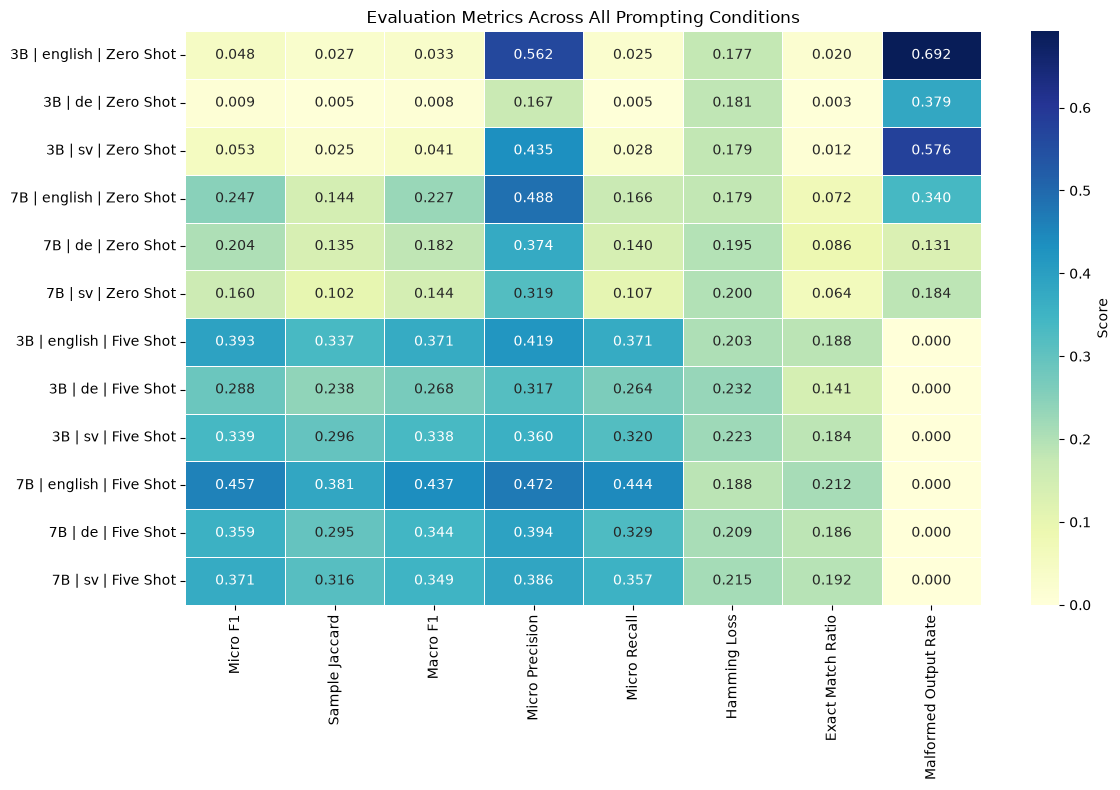

In [36]:
heatmap_df = metrics_summary_df.copy()
heatmap_df["Condition"] = (
    heatmap_df["model"] + " | " + 
    heatmap_df["target"] + " | " + 
    heatmap_df["mode"].str.replace("_", " ").str.title()
)

heatmap_df = heatmap_df.set_index("Condition")
numeric_metrics = [
    "micro_f1", "macro_f1", "sample_jaccard", "micro_precision", 
    "micro_recall", "exact_match_ratio", "hamming_loss", "malformed_output_rate"
]

numeric_metrics = [m for m in numeric_metrics if m in heatmap_df.columns]
heatmap_data = heatmap_df[numeric_metrics]

heatmap_data.columns = heatmap_data.columns.str.replace("_", " ").str.title()


plt.figure(figsize=(12, 8))

heatmap_df = metrics_plot_df.copy()

heatmap_df["Condition"] = (
    heatmap_df["model"] + " | "
    + heatmap_df["target"] + " | "
    + heatmap_df["mode"].str.replace("_", " ").str.title()
)

heatmap_data = heatmap_df.set_index("Condition").select_dtypes(include="number")
heatmap_data.columns = heatmap_data.columns.str.replace("_", " ").str.title()

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    cbar_kws={"label": "Score"},
    linewidths=0.5
)

plt.title("Evaluation Metrics Across All Prompting Conditions")
plt.ylabel("")
plt.tight_layout()
plt.show()

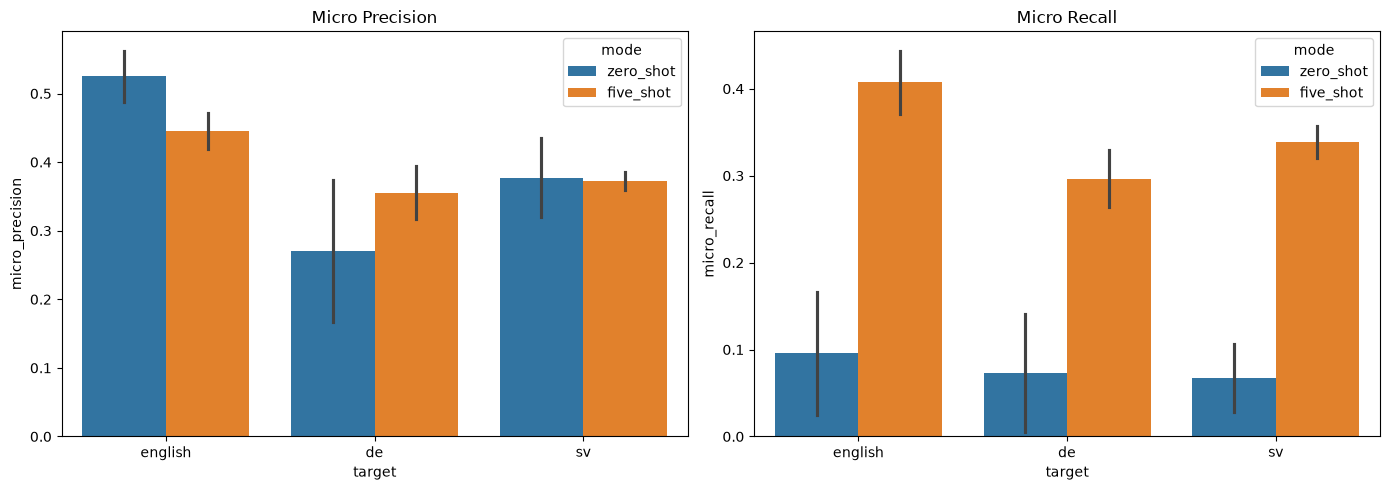

In [37]:
# Plot Precision vs Recall delta
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=metrics_summary_df, x="target", y="micro_precision", hue="mode", ax=axes[0]).set_title("Micro Precision")
sns.barplot(data=metrics_summary_df, x="target", y="micro_recall", hue="mode", ax=axes[1]).set_title("Micro Recall")
plt.tight_layout()
plt.show()

In [38]:
# Function to check if lists match exactly
def exact_match(pred, true):
    return sorted(pred) == sorted(true)

target_lang = "english"
model_size = "7B"

# Extract the relevant columns for a specific model and target
zero_shot_preds = prompting_comparison_df[(model_size, "zero_shot", target_lang)]
five_shot_preds = prompting_comparison_df[(model_size, "five_shot", target_lang)]
true_labels = prompting_comparison_df["true_labels"]

# Find rows where zero-shot was perfect, but five-shot failed
overfit_mask = (
    zero_shot_preds.combine(true_labels, exact_match) & 
    ~five_shot_preds.combine(true_labels, exact_match)
)

overfit_examples = prompting_comparison_df[overfit_mask][
    [(model_size, "zero_shot", target_lang), (model_size, "five_shot", target_lang), "true_labels"]
]

print(f"Found {len(overfit_examples)} instances of potential demonstration overfitting.")
display(overfit_examples.head(10))

KeyError: 'true_labels'

In [40]:
# Function to check if lists match exactly
def exact_match(pred, true):
    # Handle cases where true or pred might be NaN/floats from missing data
    if not isinstance(pred, list) or not isinstance(true, list):
        return False
    return sorted(pred) == sorted(true)

target_lang = "english"
model_size = "7B"

# Extract the relevant columns for a specific model and target
zero_shot_preds = prompting_comparison_df[(model_size, "zero_shot", target_lang)]
five_shot_preds = prompting_comparison_df[(model_size, "five_shot", target_lang)]

# FIX 1: Access true_labels using the 3-level tuple
true_labels = prompting_comparison_df[("metadata", "metadata", "true_labels")]

# Find rows where zero-shot was perfect, but five-shot failed
overfit_mask = (
    zero_shot_preds.combine(true_labels, exact_match) & 
    ~five_shot_preds.combine(true_labels, exact_match)
)

# FIX 2: Use the 3-level tuple in your column filter
overfit_examples = prompting_comparison_df[overfit_mask][
    [
        (model_size, "zero_shot", target_lang), 
        (model_size, "five_shot", target_lang), 
        ("metadata", "metadata", "true_labels")
    ]
]

print(f"Found {len(overfit_examples)} instances of potential demonstration overfitting.")
display(overfit_examples.head(10))

Found 5 instances of potential demonstration overfitting.


model                                       7B                          \
mode                                 zero_shot               five_shot   
target                                 english                 english   
alignment_id                                                             
en/1954/46754/6980377.xml.gz#275         [joy]     [joy, anticipation]   
en/1954/46816/4245477.xml.gz#1238   [surprise]      [disgust, sadness]   
en/1954/46816/4245477.xml.gz#1530      [anger]   [anger, anticipation]   
en/1965/59170/6988018.xml.gz#372    [surprise]          [anticipation]   
en/1990/100502/6795699.xml.gz#1149     [anger]  [anger, disgust, fear]   

model                                 metadata  
mode                                  metadata  
target                             true_labels  
alignment_id                                    
en/1954/46754/6980377.xml.gz#275         [joy]  
en/1954/46816/4245477.xml.gz#1238   [surprise]  
en/1954/46816/4245477.xml.gz#1530      [anger]  
en/1965/59170/6988018.xml.gz#372    [surprise]  
en/1990/100502/6795699.xml.gz#1149     [anger]

In [ ]:
# plot per_emotion_f1
